# 1. Import Modules

## 1.1 Python Moduels

In [1]:
import warnings
warnings.filterwarnings('ignore')
import datetime as dt
import numpy as np
import pandas as pd

from __future__ import annotations
from dataclasses import dataclass, field
from typing import Optional

In [2]:
# Enable import of other modules
import sys
ROOT = r"C:\Users\g.varvounis\Documents\RiC"
if ROOT not in sys.path:
    sys.path.append(ROOT)

## 1.2 RiC Modules

In [3]:
from model.curve_builder import CuevrBuilder

# 2. Runner

In [4]:
holidays_list = [
    # 2026
    dt.datetime(2026, 1, 1), # New Year's Day
    dt.datetime(2026, 1, 6), # Epiphany
    dt.datetime(2026, 2, 23), # Clean Monday
    dt.datetime(2026, 3, 25), # Independence Day / Annunciation
    dt.datetime(2026, 4, 10), # Orthodox Good Friday
    dt.datetime(2026, 4, 12), # Orthodox Easter Sunday
    dt.datetime(2026, 4, 13), # Orthodox Easter Monday
    dt.datetime(2026, 5, 1), # Labour Day
    dt.datetime(2026, 6, 1), # Holy Spirit Monday
    dt.datetime(2026, 8, 15), # Dormition of the Virgin Mary
    dt.datetime(2026, 10, 28), # Ochi Day
    dt.datetime(2026, 12, 25), # Christmas Day
    dt.datetime(2026, 12, 26), # Synaxis of the Mother of God
    # 2027
    dt.datetime(2027, 1, 1),
    dt.datetime(2027, 1, 6),
    dt.datetime(2027, 3, 15), # Clean Monday
    dt.datetime(2027, 3, 25),
    dt.datetime(2027, 4, 30), # Orthodox Good Friday
    dt.datetime(2027, 5, 1), # Labour Day, nominal date
    dt.datetime(2027, 5, 2), # Orthodox Easter Sunday
    dt.datetime(2027, 5, 3), # Orthodox Easter Monday
    dt.datetime(2027, 6, 21), # Holy Spirit Monday
    dt.datetime(2027, 8, 15),
    dt.datetime(2027, 10, 28),
    dt.datetime(2027, 12, 25),
    dt.datetime(2027, 12, 26),
    # 2028
    dt.datetime(2028, 1, 1),
    dt.datetime(2028, 1, 6),
    dt.datetime(2028, 2, 28), # Clean Monday
    dt.datetime(2028, 3, 25),
    dt.datetime(2028, 4, 14), # Orthodox Good Friday
    dt.datetime(2028, 4, 16), # Orthodox Easter Sunday
    dt.datetime(2028, 4, 17), # Orthodox Easter Monday
    dt.datetime(2028, 5, 1), # Labour Day
    dt.datetime(2028, 6, 5), # Holy Spirit Monday
    dt.datetime(2028, 8, 15),
    dt.datetime(2028, 10, 28),
    dt.datetime(2028, 12, 25),
    dt.datetime(2028, 12, 26)
]

valuation_date = dt.datetime(2026,10,29)
#dam_start_d = "01-01-2025"
dam_start_d = "10-10-2025"
dma_end_d = "29-10-2026"

In [5]:
cl1 = CuevrBuilder()

df_result = cl1.orchestrate_process(
    api_start="http://10.7.32.34/cdm/Quotations/GetRData/91535c0a-31eb-4906-b895-2cd0fdcf36eb?startDate=",
    api_mid="&endDate=", api_end="&dates=true&simulation=0",
    valuation_date=valuation_date,
    dam_history_start=dam_start_d, dam__history_end=dma_end_d,
    horizon_years=2, holidays=holidays_list)

INFO - Creating Output Dir...
INFO - Output Dir created sucesfully!
INFO - Importing DAM prices for GR...
INFO - DAM prices for GR imported sucesfully!!
INFO - Defining shape characteristics...
INFO - Shape characteristics defined sucessfully!!
INFO - Loading Forward Curve...
INFO - Forward Curve loaded sucesfully!!
INFO - Determining Forward Curve...
INFO - Forward Curve determined sucesfully!!


<Axes: >

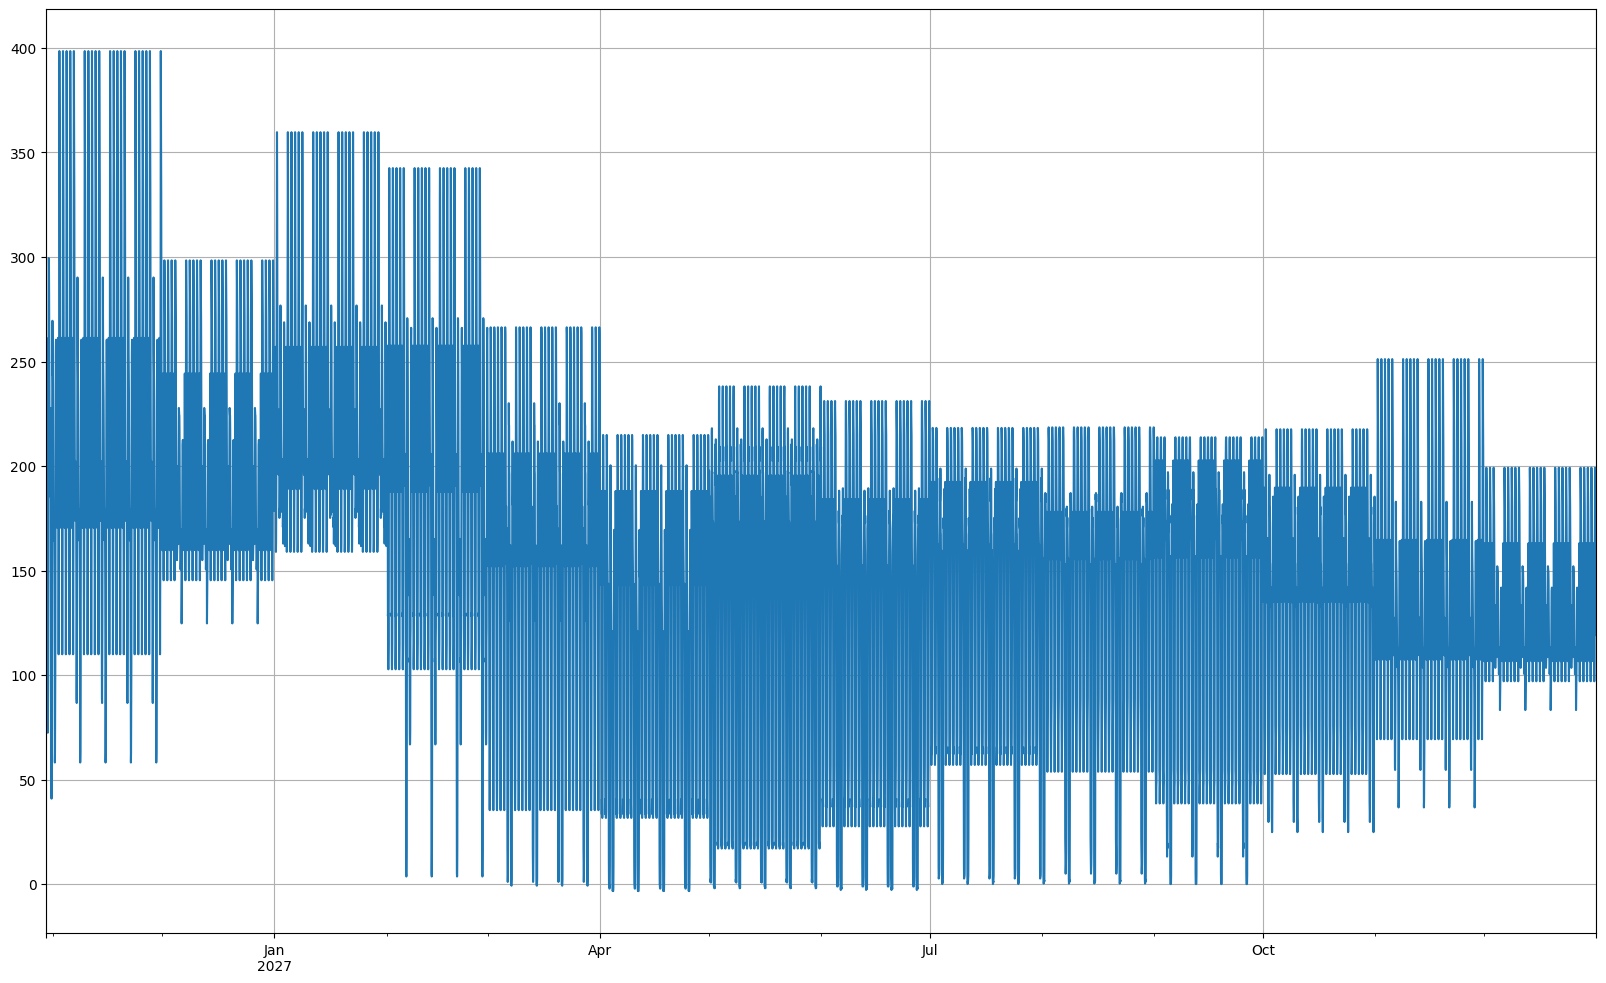

In [6]:
df_result["value"].plot(figsize=(20, 12), grid=True)

In [7]:
df_result.index

DatetimeIndex(['2026-10-30 00:00:00', '2026-10-30 01:00:00',
               '2026-10-30 02:00:00', '2026-10-30 03:00:00',
               '2026-10-30 04:00:00', '2026-10-30 05:00:00',
               '2026-10-30 06:00:00', '2026-10-30 07:00:00',
               '2026-10-30 08:00:00', '2026-10-30 09:00:00',
               ...
               '2027-12-31 14:00:00', '2027-12-31 15:00:00',
               '2027-12-31 16:00:00', '2027-12-31 17:00:00',
               '2027-12-31 18:00:00', '2027-12-31 19:00:00',
               '2027-12-31 20:00:00', '2027-12-31 21:00:00',
               '2027-12-31 22:00:00', '2027-12-31 23:00:00'],
              dtype='datetime64[ns]', length=10272, freq='h')